# Ridge regression: ATFM delay per arrival

This notebook predicts daily ATFM arrival delay per arrival at 12 German airports (2014–2025, one row per airport-day) with Ridge regression. The target `atfm_delay_per_arrival` is total ATFM arrival delay minutes divided by arrivals, so undelayed flights are included; about 89% of days are zero. Data come from `data/processed/airport_day.parquet`, and the 37 predictors are taken from the feature contract in `data/processed/feature_contract.json`. Same-day observed weather is used as a perfect forecast, so this is a retrospective study rather than a tested day-ahead forecast; history columns are assumed to be available at the start of the day, which has not been checked against EUROCONTROL publication times. The notebook complements the classification notebooks 03–04 by estimating severity rather than the risk of a disrupted day.

| Period | Years | Use |
|---|---|---|
| train | 2014–2021 | fitting |
| select | 2022 | model selection (the penalty alpha) |
| check | 2023 | second pre-test check, post-processing decisions |
| test | 2024–2025 | final evaluation, scored once |

2024–2025 was looked at in earlier project work, so it is a previously inspected period rather than a fully untouched test set. It is not used for any decision in this notebook.

The Ridge penalty is useful here because several history inputs overlap (yesterday's delay, the 7-day and the 28-day averages).

## 1. Setup

In [1]:
# 1 setup
# Imports, the fixed random seed and the paths to the data and the feature contract.
# The version printout records the environment the results were produced with.
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn

# Ridge itself has no randomness; the seed is used for the permutation importance
RANDOM_SEED = 42

# The notebooks live in notebooks/, so the repository root is one level up
PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "airport_day.parquet"
CONTRACT_PATH = PROJECT_ROOT / "data" / "processed" / "feature_contract.json"

print("Python:      ", platform.python_version())
print("pandas:      ", pd.__version__)
print("numpy:       ", np.__version__)
print("scikit-learn:", sklearn.__version__)
print()
print("Random seed:", RANDOM_SEED)
print("Data file found:    ", DATA_PATH.exists(), "->", DATA_PATH.relative_to(PROJECT_ROOT))
print("Contract file found:", CONTRACT_PATH.exists(), "->", CONTRACT_PATH.relative_to(PROJECT_ROOT))

Python:       3.13.14
pandas:       3.0.3
numpy:        2.4.6
scikit-learn: 1.9.0

Random seed: 42
Data file found:     True -> data/processed/airport_day.parquet
Contract file found: True -> data/processed/feature_contract.json


Python 3.13.14, pandas 3.0.3, numpy 2.4.6, scikit-learn 1.9.0; random seed 42. Both input files are present.

## 2. Data checks

In [2]:
# 2.1 load the dataset
# One row per airport-day; every later table is a filtered copy of this one.
airport_days = pd.read_parquet(DATA_PATH)

print("Rows:   ", airport_days.shape[0])
print("Columns:", airport_days.shape[1])

Rows:    52596
Columns: 79


Example rows for Frankfurt (EDDF). Each row is one airport on one UTC calendar day; `arrivals_atfm_delayed_15` counts arrivals with more than 15 minutes of ATFM delay.

In [3]:
# 2.2 a few rows for Frankfurt (EDDF), showing only some of the columns
# A quick look at the raw values for one airport, to see what a row contains.
example_columns = [
    "airport_icao", "airport_name", "date", "arrivals", "atfm_delay_min",
    "arrivals_atfm_delayed_15", "temp_mean_c", "gust_max_ms",
    "disrupted_day", "atfm_delay_per_arrival",
]
frankfurt_rows = airport_days[airport_days["airport_icao"] == "EDDF"]
frankfurt_rows[example_columns].head(3)

,airport_icao,airport_name,date,arrivals,atfm_delay_min,arrivals_atfm_delayed_15,temp_mean_c,gust_max_ms,disrupted_day,atfm_delay_per_arrival
1,EDDF,Frankfurt,2014-01-01 00:00:00+00:00,362.0,0.0,0.0,4.575000,8.0,0,0.0
13,EDDF,Frankfurt,2014-01-02 00:00:00+00:00,560.0,1709.0,50.0,7.429167,15.0,1,3.051786
25,EDDF,Frankfurt,2014-01-03 00:00:00+00:00,564.0,1730.0,50.0,7.704167,NaN,1,3.067376


On 2 January 2014 Frankfurt had 560 arrivals, 50 of them delayed by more than 15 minutes (8.9%, above the 2% threshold), so the day is disrupted; delay per arrival is 1,709 / 560 ≈ 3.05 minutes. The `NaN` gust on 3 January is a real gap in the weather record.

In [4]:
# 2.3 which airports and dates are covered?
# Rows, first and last date per airport. If every airport has one row per calendar day,
# rows should equal calendar_days for each airport.
coverage = airport_days.groupby(["airport_icao", "airport_name"]).agg(
    rows=("date", "size"),
    first_date=("date", "min"),
    last_date=("date", "max"),
)
calendar_days = (airport_days["date"].max() - airport_days["date"].min()).days + 1

print("Number of airports:", coverage.shape[0])
print("Calendar days from the first to the last date:", calendar_days)
coverage

Number of airports: 12
Calendar days from the first to the last date: 4383


,,rows,first_date,last_date
airport_icao,airport_name,,,
EDDC,Dresden,4383,2014-01-01 00:00:00+00:00,2025-12-31 00:00:00+00:00
EDDF,Frankfurt,4383,2014-01-01 00:00:00+00:00,2025-12-31 00:00:00+00:00
EDDG,Muenster-Osnabrueck,4383,2014-01-01 00:00:00+00:00,2025-12-31 00:00:00+00:00
EDDH,Hamburg,4383,2014-01-01 00:00:00+00:00,2025-12-31 00:00:00+00:00
EDDK,Cologne-Bonn,4383,2014-01-01 00:00:00+00:00,2025-12-31 00:00:00+00:00
EDDL,Duesseldorf,4383,2014-01-01 00:00:00+00:00,2025-12-31 00:00:00+00:00
EDDM,Munich,4383,2014-01-01 00:00:00+00:00,2025-12-31 00:00:00+00:00
EDDN,Nuremberg,4383,2014-01-01 00:00:00+00:00,2025-12-31 00:00:00+00:00
EDDP,Leipzig-Halle,4383,2014-01-01 00:00:00+00:00,2025-12-31 00:00:00+00:00


12 airports with 4,383 rows each, i.e. every day from 1 January 2014 to 31 December 2025 (12 × 4,383 = 52,596 rows, 79 columns).

In [5]:
# 2.4 is any airport-date pair listed more than once?
# The airport-day is the unit of analysis, so each (airport, date) pair must appear only once.
# duplicated() marks every repeat after the first occurrence; the sum counts them
duplicate_count = airport_days.duplicated(subset=["airport_icao", "date"]).sum()
print("Duplicate airport-date rows:", duplicate_count)

Duplicate airport-date rows: 0


No duplicate airport-days.

The feature contract, written when the dataset was built, lists the approved predictors (`predictor_allowlist`) and the same-day outcomes that must not be used as inputs (`forbidden_same_day_outcomes`).

In [6]:
# 2.5 read the feature contract
# The contract fixes which columns may be used as predictors. Same-day outcomes are forbidden
# because they are only known after the day is over and would leak the answer into the model.
import json

with open(CONTRACT_PATH) as contract_file:
    feature_contract = json.load(contract_file)

predictor_columns = feature_contract["predictor_allowlist"]
forbidden_columns = feature_contract["forbidden_same_day_outcomes"]

print("Approved predictors:", len(predictor_columns))
print("Entries in the forbidden list:", len(forbidden_columns), "| unique:", len(set(forbidden_columns)))
print("Contract note:", feature_contract["note"])

Approved predictors: 37
Entries in the forbidden list: 28 | unique: 27
Contract note: Target definition is EUROCONTROL ATFM airport arrival delay (network regulations), not gate/schedule punctuality.


37 approved predictors. The forbidden list has 28 entries but 27 distinct names (`atfm_delay_min` appears twice), which does not matter for the overlap check.

In [7]:
# 2.6 data type and missing values for every approved predictor
# Shows the stored type and the share of missing values per predictor before any conversion.
predictor_overview = pd.DataFrame({
    "dtype": airport_days[predictor_columns].dtypes.astype(str),
    "missing_rows": airport_days[predictor_columns].isna().sum(),
})
predictor_overview["missing_percent"] = (100 * predictor_overview["missing_rows"] / len(airport_days)).round(2)
predictor_overview

,dtype,missing_rows,missing_percent
airport_icao,string,0,0.00
weekday,Int8,0,0.00
month,Int8,0,0.00
doy_sin,float64,0,0.00
doy_cos,float64,0,0.00
is_weekend,bool,0,0.00
is_public_holiday,bool,0,0.00
temp_mean_c,float64,185,0.35
temp_min_c,float64,185,0.35
temp_max_c,float64,185,0.35


- Airport and calendar columns are complete.
- Weather columns are missing on 0.35–1.57% of rows; visibility and the weather-code columns (fog, thunder, snow, freezing) have the most gaps.
- History columns are missing on less than 0.6% of rows, mostly at the start of the series and after gaps.
- Data types are mixed; the input helper in section 5 converts everything except the airport code to float.

In [8]:
# 2.7 does the dataset's own 'split' column agree with the planned years?
# Sanity check: the 'split' label stored in the file should match the year ranges used below.
pd.crosstab(airport_days["year"], airport_days["split"])

split,calibrate,model_select,test,train
year,,,,
2014,0,0,0,4380
2015,0,0,0,4380
2016,0,0,0,4392
2017,0,0,0,4380
2018,0,0,0,4380
2019,0,0,0,4380
2020,0,0,0,4392
2021,0,0,0,4380
2022,0,4380,0,0


The dataset's `split` column matches the planned years. 2016, 2020 and 2024 have 4,392 rows because they are leap years.

## 3. Target distribution

Missing targets (no record, or zero arrivals) are excluded rather than set to zero. Very large values are kept, since severe days are the cases of most operational interest. Everything after the missingness count uses the training years only.

In [9]:
# 3.1 missing, infinite and negative target values in every period (counts only)
# The target is delay minutes divided by arrivals, so it is undefined on days with no record or
# no arrivals. Infinite or negative values would point to a data error. Only counts are shown.
target_values = airport_days["atfm_delay_per_arrival"].astype("float64")
print("Missing target values: ", target_values.isna().sum())
print("Infinite target values:", np.isinf(target_values).sum())
print("Negative target values:", (target_values < 0).sum())

target_missing = target_values.isna()
missing_rows = airport_days[target_missing].copy()
missing_rows["reason"] = "other"
# Later assignments overwrite earlier ones, so zero arrivals wins over a missing record
missing_rows.loc[~missing_rows["eurocontrol_row_present"], "reason"] = "no EUROCONTROL record for that day"
missing_rows.loc[missing_rows["arrivals"] == 0, "reason"] = "zero arrivals (0 / 0 is undefined)"
pd.crosstab(missing_rows["reason"], missing_rows["split"])

Missing target values:  47
Infinite target values: 0
Negative target values: 0


split,model_select,test,train
reason,,,
no EUROCONTROL record for that day,8,0,30
zero arrivals (0 / 0 is undefined),1,1,7


No infinite or negative values. 47 targets are missing: 38 with no EUROCONTROL record and 9 with zero arrivals (0 / 0). These are the same 47 rows that have no label in the classification notebooks, and they are excluded.

In [10]:
# 3.2 from here on, explore the training years only (2014-2021)
# Exploration uses 2014-2021 only, so nothing seen here can influence choices made on later years.
# The target is also rebuilt from its two raw columns to confirm the stored definition.
training_days = airport_days[(airport_days["year"] <= 2021) & ~target_missing].copy()
training_target = training_days["atfm_delay_per_arrival"].astype("float64")
print("Training rows with a known target:", len(training_days))

# Re-calculate the target from its two ingredients and compare with the stored column
recalculated = training_days["atfm_delay_min"] / training_days["arrivals"]
print("Largest difference from the stored target:", (recalculated - training_target).abs().max())

Training rows with a known target: 35027
Largest difference from the stored target: 0.0


35,027 training rows. `atfm_delay_min / arrivals` reproduces the stored target exactly.

In [11]:
# 3.3 how many training days have zero ATFM delay, and how big are the others?
# The target is mostly zeros with a long right tail. This shape matters for the choice of
# error metric and for how a linear model behaves.
zero_days = (training_target == 0).sum()
positive_target = training_target[training_target > 0]
print(f"Zero-delay days:     {zero_days} ({zero_days / len(training_target):.1%})")
print(f"Positive-delay days: {len(positive_target)} ({len(positive_target) / len(training_target):.1%})")
print()
print("All training days (minutes per arrival):")
print(training_target.describe(percentiles=[0.5, 0.9, 0.95, 0.99, 0.999]).round(3).to_string())
print()
print("Positive-delay days only:")
print(positive_target.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).round(3).to_string())

Zero-delay days:     31576 (90.1%)
Positive-delay days: 3451 (9.9%)

All training days (minutes per arrival):
count    35027.000
mean         0.192
std          0.992
min          0.000
50%          0.000
90%          0.000
95%          1.142
99%          4.362
99.9%       11.895
max         37.763

Positive-delay days only:
count    3451.000
mean        1.952
std         2.562
min         0.002
25%         0.602
50%         1.162
75%         2.271
90%         4.412
99%        11.916
max        37.763


- 31,576 training days (90.1%) have zero ATFM arrival delay; the median and the 90th percentile are both 0, and the mean is 0.19 minutes per arrival.
- On positive days only, the median is 1.16 minutes, 90% are below 4.4 minutes and the maximum is 37.8 minutes.

In [12]:
# 3.4 the ten largest training values - kept, but worth looking at
# The extreme days are kept in the data; listing them with the delay causes shows they are real events.
largest_days = training_days.sort_values("atfm_delay_per_arrival", ascending=False).head(10).copy()
# .dt.date drops the time and timezone part for a shorter display
largest_days["date"] = largest_days["date"].dt.date
largest_days[[
    "airport_icao", "airport_name", "date", "arrivals", "atfm_delay_min", "atfm_delay_per_arrival",
    "delay_weather_min", "delay_atc_capacity_min", "delay_atc_staffing_min", "delay_aerodrome_capacity_min",
]].round(2)

,airport_icao,airport_name,date,arrivals,atfm_delay_min,atfm_delay_per_arrival,delay_weather_min,delay_atc_capacity_min,delay_atc_staffing_min,delay_aerodrome_capacity_min
4321,EDDF,Frankfurt,2014-12-27,358.0,13519.0,37.76,0.0,0.0,0.0,0.0
4326,EDDM,Munich,2014-12-27,333.0,12398.0,37.23,12398.0,0.0,0.0,0.0
23439,EDDH,Hamburg,2019-05-08,216.0,6319.0,29.25,0.0,0.0,0.0,6319.0
19371,EDDH,Hamburg,2018-06-03,47.0,1094.0,23.28,0.0,0.0,0.0,0.0
13261,EDDF,Frankfurt,2017-01-10,494.0,11310.0,22.89,11310.0,0.0,0.0,0.0
2509,EDDF,Frankfurt,2014-07-29,652.0,14216.0,21.8,14216.0,0.0,0.0,0.0
3553,EDDF,Frankfurt,2014-10-24,709.0,15195.0,21.43,15195.0,0.0,0.0,0.0
17269,EDDF,Frankfurt,2017-12-10,427.0,8252.0,19.33,0.0,0.0,0.0,0.0
18428,EDDP,Leipzig-Halle,2018-03-16,111.0,2133.0,19.22,2133.0,0.0,0.0,0.0
19465,EDDF,Frankfurt,2018-06-11,681.0,12872.0,18.9,12872.0,0.0,0.0,0.0


The largest value is Frankfurt on 27 December 2014 (13,519 minutes over 358 arrivals, 37.8 minutes per arrival), coded under a cause not shown here; Munich had almost the same value on that day, coded as weather. Most other extreme days are weather-coded; Hamburg on 8 May 2019 is aerodrome capacity.

Hamburg on 3 June 2018 had only 47 arrivals, so 1,094 minutes became 23.3 minutes per arrival. With so few arrivals the ratio is unstable, and it is not clear from the data whether this was a closure or an incomplete record. All these days are kept.

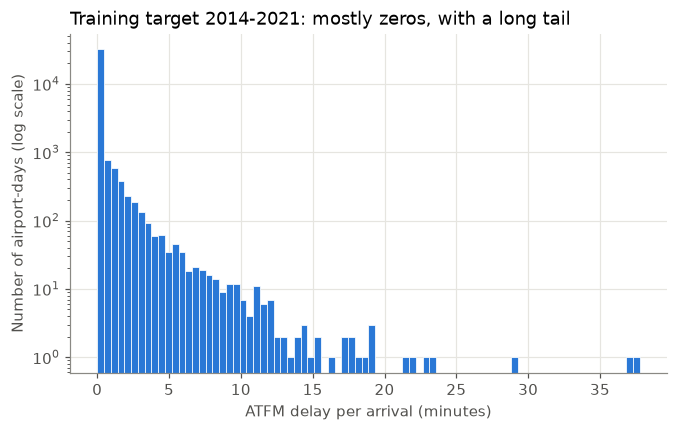

In [13]:
# 3.5 plot style and a histogram of the training target
# Sets one plot style for the notebook, then shows the target distribution.
# The y-axis is logarithmic so that both the many zero days and the rare large values are visible.
import matplotlib.pyplot as plt

# One consistent, quiet style for every plot in this notebook
plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e0",
    "axes.edgecolor": "#8a8984",
    "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
})
MODEL_COLOR = "#2a78d6"      # blue: the model
SECOND_COLOR = "#eb6834"     # orange: second line (benchmark or alternative)
THIRD_COLOR = "#1baf7a"      # green: third line
REFERENCE_COLOR = "#8a8984"  # grey: reference lines

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(training_target, bins=80, color=MODEL_COLOR, edgecolor="white", linewidth=0.5)
ax.set_yscale("log")
ax.set_xlabel("ATFM delay per arrival (minutes)")
ax.set_ylabel("Number of airport-days (log scale)")
ax.set_title("Training target 2014-2021: mostly zeros, with a long tail", loc="left")
ax.set_axisbelow(True)
plt.show()

All 31,576 zero-delay training days fall in the first bin; counts then decline steadily up to about 20 minutes, with a few isolated days beyond (log y-axis).

In [14]:
# 3.6 the target by airport (training years)
# Average delay, largest value and share of zero-delay days per airport (training years).
# Airports differ strongly, which is why the airport is used as a predictor.
# Helper column so that the share of zero days can be computed as a mean in agg()
training_days["is_zero_delay"] = training_target == 0
training_by_airport = training_days.groupby(["airport_icao", "airport_name"]).agg(
    days=("atfm_delay_per_arrival", "size"),
    mean_delay=("atfm_delay_per_arrival", "mean"),
    largest_delay=("atfm_delay_per_arrival", "max"),
    share_zero_days=("is_zero_delay", "mean"),
)
training_by_airport.sort_values("mean_delay", ascending=False).round(3)

,,days,mean_delay,largest_delay,share_zero_days
airport_icao,airport_name,,,,
EDDF,Frankfurt,2922,0.742,37.763,0.770
EDDL,Duesseldorf,2922,0.375,18.069,0.704
EDDM,Munich,2922,0.316,37.231,0.829
EDDH,Hamburg,2922,0.315,29.255,0.868
EDDK,Cologne-Bonn,2922,0.219,13.019,0.818
EDDP,Leipzig-Halle,2922,0.158,19.216,0.928
EDDW,Bremen,2919,0.088,16.232,0.958
EDDS,Stuttgart,2906,0.077,7.878,0.957
EDDV,Hannover,2922,0.01,5.47,0.994


- Frankfurt has the highest mean (0.74 minutes per arrival). Düsseldorf has the fewest zero days (70%), Frankfurt 77%.
- Düsseldorf, Munich and Hamburg follow at about 0.3–0.4 minutes. Munich's worst day (37.2) is almost as extreme as Frankfurt's.
- Münster-Osnabrück, Dresden, Nuremberg and Hannover have zero delay on 99.4–100% of days.

In [15]:
# 3.7 the target by year (training years)
# The same summary by year, showing the COVID years and the change in delay levels over time.
training_by_year = training_days.groupby("year").agg(
    days=("atfm_delay_per_arrival", "size"),
    mean_delay=("atfm_delay_per_arrival", "mean"),
    share_zero_days=("is_zero_delay", "mean"),
)
training_by_year.round(3)

,days,mean_delay,share_zero_days
year,,,
2014,4380,0.213,0.918
2015,4380,0.163,0.925
2016,4392,0.211,0.905
2017,4380,0.241,0.867
2018,4380,0.299,0.842
2019,4380,0.272,0.847
2020,4358,0.036,0.982
2021,4377,0.102,0.927


Mean delay peaked in 2018 (0.30 minutes) and fell to 0.036 in 2020 (98% zero days) with the COVID traffic collapse. 2020–2021 therefore behave very differently from the other training years, but they remain in the training data.

## 4. Predictors

The target is `atfm_delay_min / arrivals`, so both ingredients, the cause breakdown, delayed-flight counts and the disruption labels are same-day outcomes and are excluded to avoid leakage. History columns such as `delay_per_arrival_lag1` and `delay_per_arrival_mean_28d` use only earlier days and are allowed.

In [16]:
# 4.1 group the approved predictors by when their information is available
# Each predictor has an availability assumption in the contract (for example known the day before).
# Grouping by it shows that only information available before the day is used.
predictor_info = pd.DataFrame(feature_contract["predictors"])
predictor_info = predictor_info[predictor_info["name"].isin(predictor_columns)]
print("Approved predictors described in the contract:", len(predictor_info))
print()

for availability, group in predictor_info.groupby("availability_assumption"):
    print(f"{availability}  ({len(group)} columns)")
    print("   ", ", ".join(group["name"]))
    print()

Approved predictors described in the contract: 37

Computed from days strictly before the row's day (known at the start of the day)  (10 columns)
    arrivals_lag1, arrivals_lag7, arrivals_mean_7d, delay_per_arrival_lag1, share_delayed15_lag1, disrupted_lag1, delay_per_arrival_mean_7d, delay_per_arrival_mean_28d, disrupted_rate_28d, weather_delay_per_arrival_mean_28d

Known in advance  (7 columns)
    airport_icao, weekday, month, doy_sin, doy_cos, is_weekend, is_public_holiday

Same-day OBSERVED weather standing in for a day-ahead forecast (perfect-forecast assumption; scores are an upper bound)  (20 columns)
    temp_mean_c, temp_min_c, temp_max_c, frost_day, rh_mean_pct, wind_mean_ms, wind_max_ms, gust_max_ms, gust_hours_ge15, precip_sum_mm, precip_max_1h_mm, precip_hours, cold_precip_hours, vis_min_m, low_vis_hours_lt1000, vis_hours_lt5000, fog_hours, thunder_hours, snow_hours, freezing_hours



- 7 columns are known in advance (airport and calendar).
- 20 columns are same-day observed weather. This is where the perfect-forecast assumption applies, and the contract notes that scores are therefore an upper bound.
- 10 columns are history computed from earlier days only.

In [17]:
# 4.2 make sure the target, its ingredients and other forbidden columns are not predictors
# Leakage check: the target and the two columns it is computed from (delay minutes and arrivals)
# must not be predictors, nor any other forbidden same-day outcome.
overlap = set(predictor_columns) & set(forbidden_columns)
print("Predictors that are also forbidden outcomes:", sorted(overlap))
for column in ["atfm_delay_per_arrival", "atfm_delay_min", "arrivals"]:
    print(f"Is {column} in the predictor list? {column in predictor_columns}")

unused_columns = []
for column in airport_days.columns:
    if column not in predictor_columns:
        unused_columns.append(column)
print()
print(len(unused_columns), "columns are NOT used as predictors:")
print(", ".join(unused_columns))

Predictors that are also forbidden outcomes: []
Is atfm_delay_per_arrival in the predictor list? False
Is atfm_delay_min in the predictor list? False
Is arrivals in the predictor list? False

42 columns are NOT used as predictors:
date, airport_name, dwd_station, arrivals, atfm_delay_min, arrivals_atfm_delayed, arrivals_atfm_delayed_15, atfm_version, delay_accident_min, delay_atc_capacity_min, delay_deicing_min, delay_equipment_non_atc_min, delay_aerodrome_capacity_min, delay_atc_industrial_min, delay_airspace_mgmt_min, delay_industrial_non_atc_min, delay_other_min, delay_special_event_min, delay_atc_routeing_min, delay_atc_staffing_min, delay_equipment_atc_min, delay_environment_min, delay_weather_min, delay_not_specified_min, delay_blank_in_source, eurocontrol_row_present, temp_valid_hours, wind_valid_hours, gust_valid_hours, precip_valid_hours, vis_valid_hours, ww_reported_hours, atfm_delay_per_arrival, share_arrivals_delayed_15, weather_delay_per_arrival, disrupted_day, severe_disr

No approved predictor is on the forbidden list; the target, `atfm_delay_min` and `arrivals` are all excluded. The same 42 columns are left out as in the classification notebooks.

In [18]:
# 4.3 a lag column is yesterday's value moved forward by one day (Frankfurt, a week in July 2019)
# Shows on real rows that delay_per_arrival_lag1 on day t equals atfm_delay_per_arrival on day t-1,
# so the lag predictors only use past information.
lag_example = airport_days[
    (airport_days["airport_icao"] == "EDDF")
    # the stored dates are timezone-aware (UTC), so the comparison timestamps must be as well
    & (airport_days["date"] >= pd.Timestamp("2019-07-01", tz="UTC"))
    & (airport_days["date"] <= pd.Timestamp("2019-07-05", tz="UTC"))
]
lag_example[["date", "atfm_delay_per_arrival", "delay_per_arrival_lag1", "disrupted_day", "disrupted_lag1"]]

,date,atfm_delay_per_arrival,delay_per_arrival_lag1,disrupted_day,disrupted_lag1
24085,2019-07-01 00:00:00+00:00,0.946309,0.000000,1,0.0
24097,2019-07-02 00:00:00+00:00,0.0,0.946309,0,1.0
24109,2019-07-03 00:00:00+00:00,0.0,0.000000,0,0.0
24121,2019-07-04 00:00:00+00:00,0.0,0.000000,0,0.0
24133,2019-07-05 00:00:00+00:00,0.0,0.000000,0,0.0


On 1 July 2019 Frankfurt had 0.946 minutes per arrival and was disrupted; on 2 July `delay_per_arrival_lag1 = 0.946` and `disrupted_lag1 = 1`, i.e. the previous day's values.

## 5. Time-based split

Splitting by calendar year keeps evaluation days after training days and puts all airports on a given date in the same period. The 2024–2025 target is not summarised until section 11.

In [19]:
# 5.1 one table per period, keeping only rows with a defined target
# Time-ordered split: train 2014-2021, select 2022 (choosing alpha), check 2023 (decision about
# clipping and robustness checks), test 2024-2025 (used once). The 2023 table keeps the name calibrate_days.
has_target = airport_days["atfm_delay_per_arrival"].notna()

# .copy() so that later column changes on a period table do not touch airport_days
train_days = airport_days[(airport_days["year"] <= 2021) & has_target].copy()
select_days = airport_days[(airport_days["year"] == 2022) & has_target].copy()
calibrate_days = airport_days[(airport_days["year"] == 2023) & has_target].copy()
test_days = airport_days[(airport_days["year"] >= 2024) & has_target].copy()

period_tables = {
    "train 2014-2021": train_days,
    "select 2022": select_days,
    "check 2023": calibrate_days,
    "test 2024-2025": test_days,
}

summary_rows = []
for period_name, table in period_tables.items():
    summary_rows.append({
        "period": period_name,
        "rows": len(table),
        "first_date": table["date"].min().date(),
        "last_date": table["date"].max().date(),
    })
print("Rows dropped because the target is undefined:", (~has_target).sum())
pd.DataFrame(summary_rows)

Rows dropped because the target is undefined: 47


,period,rows,first_date,last_date
0,train 2014-2021,35027,2014-01-01,2021-12-31
1,select 2022,4371,2022-01-01,2022-12-31
2,check 2023,4380,2023-01-01,2023-12-31
3,test 2024-2025,8771,2024-01-01,2025-12-31


35,027 training rows, 4,371 for 2022, 4,380 for 2023 and 8,771 for 2024–2025, after dropping the 47 rows with an undefined target.

In [20]:
# 5.2 target summary in the pre-test periods, and a check that no date is in two periods
# Target level and share of zero days before the test period, plus a check that the periods
# do not overlap in time. The test targets are not looked at here.
for period_name in ["train 2014-2021", "select 2022", "check 2023"]:
    values = period_tables[period_name]["atfm_delay_per_arrival"].astype("float64")
    print(f"{period_name}: mean {values.mean():.3f} min/arrival, zero-delay days {(values == 0).mean():.1%}")
print("test 2024-2025: not inspected until section 11")

date_and_period = []
for period_name, table in period_tables.items():
    date_and_period.append(pd.DataFrame({"date": table["date"], "period": period_name}))
date_and_period = pd.concat(date_and_period)
# nunique() counts the distinct periods per date; a value of 1 means no date is shared
periods_per_date = date_and_period.groupby("date")["period"].nunique()
print()
print("Largest number of periods any single date appears in:", periods_per_date.max())

train 2014-2021: mean 0.192 min/arrival, zero-delay days 90.1%
select 2022: mean 0.193 min/arrival, zero-delay days 88.6%
check 2023: mean 0.328 min/arrival, zero-delay days 84.7%
test 2024-2025: not inspected until section 11

Largest number of periods any single date appears in: 1


| Period | Mean delay (min per arrival) | Zero-delay days |
|---|---|---|
| Training | 0.192 | 90.1% |
| 2022 | 0.193 | 88.6% |
| 2023 | 0.328 | 84.7% |

2023 had about 70% more delay per arrival than the training average. No date appears in two periods.

The input helper converts boolean and integer columns to float, keeps missing values as `NaN` for imputation in section 7, and keeps the airport code as text for one-hot encoding.

In [21]:
# 5.3 build the model inputs (X) and the target (y) for each period
# Turns each period table into the predictor table X and the target y in exactly the same way.
# Encoding, missing-value filling and scaling happen later inside the sklearn pipeline.
def make_model_inputs(table):
    """Build the predictor table X and the numeric target y for one period.

    airport_icao is kept as text so the one-hot encoder in the pipeline can
    read it; all other predictors become float64 with NaN for missing values,
    which the pipeline fills later.

    Args:
        table: rows of airport_days for one period.

    Returns:
        (features, target): a DataFrame with the predictor columns and a float Series
        of ATFM delay minutes per arrival.
    """
    features = table[predictor_columns].copy()
    for column in predictor_columns:
        if column == "airport_icao":
            features[column] = features[column].astype(str)
        else:
            # True/False and whole-number columns become ordinary decimal numbers; missing stays NaN
            features[column] = features[column].astype("float64")
    target = table["atfm_delay_per_arrival"].astype("float64")
    return features, target


X_train, y_train = make_model_inputs(train_days)
X_select, y_select = make_model_inputs(select_days)
X_calibrate, y_calibrate = make_model_inputs(calibrate_days)
X_test, y_test = make_model_inputs(test_days)

print("X_train:    ", X_train.shape)
print("X_select:   ", X_select.shape)
print("X_calibrate:", X_calibrate.shape, "(the 2023 check period)")
print("X_test:     ", X_test.shape)

X_train:     (35027, 37)
X_select:    (4371, 37)
X_calibrate: (4380, 37) (the 2023 check period)
X_test:      (8771, 37)


All four input tables have the same 37 columns.

## 6. Benchmarks and metrics

MAE is the main metric, fixed before any model was trained; RMSE and R² are reported alongside. For a constant prediction, MAE is minimised by the median and squared error by the mean, which differ sharply on this target. The benchmarks are the training median (which is 0, so this is the always-zero rule), the training mean, and the previous 28-day average `delay_per_arrival_mean_28d` (missing values filled with the training median).

In [22]:
# 6.1 one small helper that scores predictions
# The three error measures used throughout. MAE is the main one (average absolute error in minutes
# per arrival); RMSE gives large errors more weight; R2 compares against predicting the period mean.
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


def regression_scores(y_true, prediction):
    """Score numeric predictions against the true target.

    Returns:
        dict with MAE, RMSE (square root of the mean squared error) and R2.
    """
    return {
        "MAE": mean_absolute_error(y_true, prediction),
        "RMSE": np.sqrt(mean_squared_error(y_true, prediction)),
        "R2": r2_score(y_true, prediction),
    }

In [23]:
# 6.2 the benchmark rules
# Benchmarks the model must beat: the training median (which is zero, since most days have no delay),
# the training mean, and each airport's average over the previous 28 days.
training_median = y_train.median()
training_mean = y_train.mean()
print(f"Training median: {training_median:.4f} minutes per arrival (so the median benchmark = zero-delay benchmark)")
print(f"Training mean:   {training_mean:.4f} minutes per arrival")


def rolling_mean_benchmark(table):
    """Return the previous 28-day average delay per arrival for each row.

    Days without 28 days of history have no value; they get the training
    median (zero) so the benchmark gives a prediction for every row.
    """
    values = table["delay_per_arrival_mean_28d"].astype("float64")
    return values.fillna(training_median).to_numpy()


print()
print("Rows with no 28-day history (filled with the training median):")
for period_name, table in period_tables.items():
    print(f"  {period_name}: {table['delay_per_arrival_mean_28d'].isna().sum()}")

Training median: 0.0000 minutes per arrival (so the median benchmark = zero-delay benchmark)
Training mean:   0.1923 minutes per arrival

Rows with no 28-day history (filled with the training median):
  train 2014-2021: 260
  select 2022: 14
  check 2023: 0
  test 2024-2025: 0


The training median is exactly 0 and the training mean is 0.192. The 28-day history is missing for 260 training rows and 14 rows in 2022; these are filled with 0.

In [24]:
# 6.3 benchmark scores on the two pre-test periods
# Scores the three benchmarks on 2022 and 2023, which gives the bar the model has to clear
# before the test period is used.
benchmark_rows = []
for period_name, table, y_true in [("select 2022", select_days, y_select), ("check 2023", calibrate_days, y_calibrate)]:
    # np.full repeats one constant value for every day in the period
    benchmark_predictions = {
        "training median (= zero delay)": np.full(len(y_true), training_median),
        "training mean": np.full(len(y_true), training_mean),
        "previous 28-day average": rolling_mean_benchmark(table),
    }
    for benchmark_name, prediction in benchmark_predictions.items():
        row = {"period": period_name, "benchmark": benchmark_name}
        row.update(regression_scores(y_true, prediction))
        benchmark_rows.append(row)

benchmark_results = pd.DataFrame(benchmark_rows)
benchmark_results.round(4)

,period,benchmark,MAE,RMSE,R2
0,select 2022,training median (= zero delay),0.1931,0.8195,-0.0588
1,select 2022,training mean,0.3427,0.7964,-0.0000
2,select 2022,previous 28-day average,0.2436,0.7396,0.1375
3,check 2023,training median (= zero delay),0.3285,1.5429,-0.0475
4,check 2023,training mean,0.4632,1.5137,-0.0082
5,check 2023,previous 28-day average,0.4227,1.4427,0.0842


- On MAE, always zero is clearly best: 0.193 on 2022 and 0.329 on 2023, against 0.244 and 0.423 for the 28-day average and 0.343 and 0.463 for the training mean. With almost 90% zero days, a zero prediction is exactly right on most rows.
- On RMSE the order reverses: always zero is worst and the 28-day average is best (0.740 and 1.443).
- R² is low throughout; the 28-day average explains only 8–14% of the variance.

A model therefore has to beat always zero on MAE, while most of the useful signal concerns the few bad days.

## 7. Preprocessing

Missing values are filled with training medians, numeric columns are standardised with training statistics, and the airport is one-hot encoded, all inside one scikit-learn pipeline fitted on 2014–2021 only. `weekday` and `month` stay ordinal as in the contract, which forces a monotone effect in a linear model; the yearly cycle is mainly carried by `doy_sin` and `doy_cos`.

In [25]:
# 7.1 filling missing values with training medians (demonstration)
# Ridge cannot handle NaN, so missing numeric values are filled with the training median.
# The medians come from training only, so no information from later years is used.
numeric_columns = []
# every predictor except the airport code is numeric
for column in predictor_columns:
    if column != "airport_icao":
        numeric_columns.append(column)

training_medians = X_train[numeric_columns].median()
fill_overview = pd.DataFrame({
    "training_median": training_medians,
    "missing_in_train": X_train[numeric_columns].isna().sum(),
    "missing_in_2022": X_select[numeric_columns].isna().sum(),
    "missing_in_2023": X_calibrate[numeric_columns].isna().sum(),
})
print("Numeric predictors:", len(numeric_columns))
fill_overview[fill_overview["missing_in_train"] + fill_overview["missing_in_2022"] + fill_overview["missing_in_2023"] > 0]

Numeric predictors: 36


,training_median,missing_in_train,missing_in_2022,missing_in_2023
temp_mean_c,10.604167,2,8,120
temp_min_c,6.400000,2,8,120
temp_max_c,14.700000,2,8,120
frost_day,0.000000,2,8,120
rh_mean_pct,77.666667,5,8,125
wind_mean_ms,3.216667,118,18,77
wind_max_ms,5.400000,118,18,77
gust_max_ms,9.800000,132,18,79
gust_hours_ge15,0.000000,132,18,79
precip_sum_mm,0.000000,92,18,49


The training median is 0 for most weather count columns and 10,000 m for visibility, so imputation assumes an ordinary day.

Missing visibility and weather-code values are much more common in 2022 and 2023 (about 330–350 rows per year) than in all eight training years combined (1 row). On those days the model sees typical weather whether or not there was fog or a thunderstorm; this is a data limitation that is not addressed here.

In [26]:
# 7.2 standardizing (demonstration on three columns)
# The ridge penalty depends on the size of each coefficient, so predictors are put on one scale
# (mean 0, standard deviation 1). The scaler is fitted on training data only. This cell is a demonstration.
from sklearn.preprocessing import StandardScaler

demo_columns = ["temp_mean_c", "gust_max_ms", "arrivals_lag1"]
demo_filled = X_train[demo_columns].fillna(training_medians[demo_columns])
# fit() learns the training mean and standard deviation of each column; transform() applies them
demo_scaler = StandardScaler().fit(demo_filled)
demo_scaled = pd.DataFrame(demo_scaler.transform(demo_filled), columns=demo_columns)

pd.DataFrame({
    "mean_before": demo_filled.mean(),
    "std_before": demo_filled.std(),
    "mean_after": demo_scaled.mean(),
    "std_after": demo_scaled.std(),
}).round(3)

,mean_before,std_before,mean_after,std_after
temp_mean_c,10.795,7.051,0.0,1.0
gust_max_ms,10.433,4.047,-0.0,1.0
arrivals_lag1,173.756,188.465,0.0,1.0


After scaling, each column has mean 0 and standard deviation 1 (before: temperature spread about 7 °C, arrivals about 188 flights).

In [27]:
# 7.3 one-hot encoding the airport (demonstration)
# A linear model needs the airport as numbers, so each airport becomes its own 0/1 column.
# handle_unknown="ignore" gives an all-zero row for an airport not seen in training instead of an error.
from sklearn.preprocessing import OneHotEncoder

demo_encoder = OneHotEncoder(handle_unknown="ignore")
demo_encoder.fit(X_train[["airport_icao"]])
print("Airports learned from training:", list(demo_encoder.categories_[0]))

three_airports = X_train[["airport_icao"]].drop_duplicates().head(3)
pd.DataFrame(
    # transform returns a sparse matrix; toarray() makes it dense for display
    demo_encoder.transform(three_airports).toarray(),
    index=three_airports["airport_icao"],
    columns=demo_encoder.get_feature_names_out(),
).astype(int)

Airports learned from training: ['EDDC', 'EDDF', 'EDDG', 'EDDH', 'EDDK', 'EDDL', 'EDDM', 'EDDN', 'EDDP', 'EDDS', 'EDDV', 'EDDW']


,airport_icao_EDDC,airport_icao_EDDF,airport_icao_EDDG,airport_icao_EDDH,airport_icao_EDDK,airport_icao_EDDL,airport_icao_EDDM,airport_icao_EDDN,airport_icao_EDDP,airport_icao_EDDS,airport_icao_EDDV,airport_icao_EDDW
airport_icao,,,,,,,,,,,,
EDDC,1,0,0,0,0,0,0,0,0,0,0,0
EDDF,0,1,0,0,0,0,0,0,0,0,0,0
EDDG,0,0,1,0,0,0,0,0,0,0,0,0


In [28]:
# 7.4 the same three operations combined in one pipeline
# Puts median filling, standardizing and one-hot encoding into one ColumnTransformer. Inside a Pipeline
# these steps are re-fitted on whatever data the model is trained on, so later periods cannot leak in.
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline


def make_preprocessor():
    """Return a new, unfitted preprocessing step for the Ridge pipeline.

    Numeric columns are filled with their median and then standardized;
    airport_icao is one-hot encoded. A function is used so that every model
    gets its own fresh copy instead of sharing one fitted object.
    """
    numeric_steps = Pipeline([
        ("fill_missing", SimpleImputer(strategy="median")),
        ("standardize", StandardScaler()),
    ])
    return ColumnTransformer([
        ("numeric", numeric_steps, numeric_columns),
        ("airport", OneHotEncoder(handle_unknown="ignore"), ["airport_icao"]),
    ])


check_preprocessor = make_preprocessor().fit(X_train)
X_train_prepared = check_preprocessor.transform(X_train)
print("Columns before preprocessing:", X_train.shape[1])
print("Columns after preprocessing: ", X_train_prepared.shape[1], "(36 numeric + 12 airport columns)")
print("Missing values left after preprocessing:", np.isnan(X_train_prepared).sum())

Columns before preprocessing: 37
Columns after preprocessing:  48 (36 numeric + 12 airport columns)
Missing values left after preprocessing: 0


The 37 inputs become 48 model columns (36 numeric and 12 airport indicators) with no missing values.

## 8. First model

Ridge with `alpha = 1.0`, fitted on 2014–2021 and scored on 2022. Ridge minimises squared error and so targets the conditional mean rather than the median, which is expected to hurt MAE on a mostly-zero target.

In [29]:
# 8.1 fit a first Ridge Regression on 2014-2021 and score it on 2022
# A first Ridge model with the default penalty (alpha=1). The Pipeline first applies the preprocessing
# learned from 2014-2021 and then fits the linear model on the result.
from sklearn.linear_model import Ridge

first_model = Pipeline([
    ("preprocess", make_preprocessor()),
    ("regressor", Ridge(alpha=1.0)),
])
first_model.fit(X_train, y_train)

first_select_prediction = first_model.predict(X_select)
first_model_scores = regression_scores(y_select, first_select_prediction)
for metric_name, value in first_model_scores.items():
    print(f"{metric_name}: {value:.4f}")

MAE: 0.2956
RMSE: 0.7256
R2: 0.1699


2022 MAE is 0.296, worse than always zero (0.193) and the 28-day average (0.244). RMSE (0.726) and R² (0.17) are better than every benchmark, consistent with a model that targets the mean.

In [30]:
# 8.2 what do the 2022 predictions look like?
# A linear model can predict below zero, although delay cannot be negative. This cell counts how
# often that happens on 2022 and compares the mean prediction with the actual mean.
print(f"Average prediction in 2022:   {first_select_prediction.mean():.3f}")
print(f"Average actual delay in 2022: {y_select.mean():.3f}")
print(f"Negative predictions in 2022: {(first_select_prediction < 0).sum()} of {len(first_select_prediction)}")
print()
print(pd.Series(first_select_prediction).describe(percentiles=[0.1, 0.5, 0.9, 0.99]).round(3).to_string())

Average prediction in 2022:   0.159
Average actual delay in 2022: 0.193
Negative predictions in 2022: 1807 of 4371

count    4371.000
mean        0.159
std         0.357
min        -0.564
10%        -0.134
50%         0.042
90%         0.634
99%         1.433
max         2.705


1,807 of 4,371 predictions for 2022 (41%) are negative, the smallest being −0.56. The median prediction is 0.04 and the largest 2.7 minutes, far below the largest actual values. The mean prediction (0.159) is slightly below the actual mean (0.193).

## 9. Tuning

`alpha` ∈ {0.1, 1, 10, 100, 1,000}. The selection rule, fixed in advance, is the lowest 2022 MAE. Refitting on 2014–2022 and scoring 2023 is a robustness check only and does not affect the choice.

In [31]:
# 9.1 try five penalty strengths, train on 2014-2021, score on 2022
# Alpha is the strength of the penalty on large coefficients: larger alpha shrinks the coefficients more.
# Five values spaced by a factor of 10 are tried; each is trained on 2014-2021 and scored on 2022.
alpha_values = [0.1, 1.0, 10.0, 100.0, 1000.0]

tuning_rows = []
for alpha in alpha_values:
    candidate = Pipeline([
        ("preprocess", make_preprocessor()),
        ("regressor", Ridge(alpha=alpha)),
    ])
    candidate.fit(X_train, y_train)
    select_prediction = candidate.predict(X_select)

    row = {"alpha": alpha}
    row.update(regression_scores(y_select, select_prediction))
    row["negative_predictions"] = int((select_prediction < 0).sum())
    tuning_rows.append(row)

tuning_results = pd.DataFrame(tuning_rows)
tuning_results.round(4)

,alpha,MAE,RMSE,R2,negative_predictions
0,0.1,0.2956,0.7256,0.1699,1808
1,1.0,0.2956,0.7256,0.1699,1807
2,10.0,0.2956,0.7256,0.1699,1804
3,100.0,0.2951,0.7258,0.1696,1803
4,1000.0,0.2928,0.7260,0.1690,1761


MAE stays at 0.2951–0.2956 for alpha from 0.1 to 100 and improves slightly to 0.2928 at 1,000, with RMSE marginally worse. With 35,000 training rows and 48 columns the weights are well determined, so only a very large penalty has a visible effect.

In [32]:
# 9.2 apply the selection rule (lowest 2022 MAE)
# The rule fixed before looking at the results: keep the alpha with the lowest 2022 MAE.
# idxmin returns the row label of the lowest MAE, loc then picks that whole row
best_row = tuning_results.loc[tuning_results["MAE"].idxmin()]
best_alpha = float(best_row["alpha"])
print("Chosen alpha:", best_alpha)
print(f"2022 MAE: {best_row['MAE']:.4f}")

Chosen alpha: 1000.0
2022 MAE: 0.2928


`alpha = 1000` has the lowest 2022 MAE and is selected. It lies at the edge of the grid, but the grid was not extended because the whole range spans only 0.003 minutes per arrival.

In [33]:
# 9.3 robustness check only - refit on 2014-2022 and score on 2023
# Refits every alpha on 2014-2022 and scores it on 2023. This only checks whether the 2022 ranking
# holds one year later; it does not change the choice of alpha.
X_train_and_select = pd.concat([X_train, X_select])
y_train_and_select = pd.concat([y_train, y_select])

check_rows = []
for alpha in alpha_values:
    candidate = Pipeline([
        ("preprocess", make_preprocessor()),
        ("regressor", Ridge(alpha=alpha)),
    ])
    candidate.fit(X_train_and_select, y_train_and_select)
    check_prediction = candidate.predict(X_calibrate)
    check_rows.append({
        "alpha": alpha,
        "MAE_2022 (train 2014-2021)": tuning_results.loc[tuning_results["alpha"] == alpha, "MAE"].iloc[0],
        "MAE_2023 (train 2014-2022)": mean_absolute_error(y_calibrate, check_prediction),
        "RMSE_2023 (train 2014-2022)": np.sqrt(mean_squared_error(y_calibrate, check_prediction)),
    })

pd.DataFrame(check_rows).round(4)

,alpha,MAE_2022 (train 2014-2021),MAE_2023 (train 2014-2022),RMSE_2023 (train 2014-2022)
0,0.1,0.2956,0.4080,1.3087
1,1.0,0.2956,0.4080,1.3087
2,10.0,0.2956,0.4080,1.3088
3,100.0,0.2951,0.4080,1.3093
4,1000.0,0.2928,0.4077,1.3124


On 2023, MAE ranges from 0.4077 to 0.4080 across all five values, and RMSE is again slightly worse at 1,000. The penalty strength hardly matters for this dataset.

The model is now fixed: Ridge with the selected `alpha`, trained on 2014–2021.

In [34]:
# 9.4 the frozen model - chosen alpha, trained on 2014-2021
# Refits the chosen alpha on 2014-2021. This model is not changed after this cell.
final_model = Pipeline([
    ("preprocess", make_preprocessor()),
    ("regressor", Ridge(alpha=best_alpha)),
])
final_model.fit(X_train, y_train)

final_select_prediction = final_model.predict(X_select)
print(f"Frozen model, 2022 MAE: {mean_absolute_error(y_select, final_select_prediction):.4f}")

Frozen model, 2022 MAE: 0.2928


The frozen model (alpha = 1,000) reproduces the 2022 MAE of 0.2928.

## 10. Negative predictions

A linear model can predict below zero although the target cannot. The rule, fixed before the test years, is to compare raw and clipped-at-zero predictions on 2023 and clip if 2023 MAE does not get worse. Clipping can only help or tie when the true value is non-negative, but it is checked anyway, and the unclipped test result is reported alongside. A transformed target such as log(1 + delay) is left as a possible extension.

In [35]:
# 10.1 how many negative predictions does the final model make before the test years?
# Counts negative predictions of the frozen model on 2022 and 2023, before deciding about clipping.
calibrate_prediction_raw = final_model.predict(X_calibrate)
for period_name, prediction in [("select 2022", final_select_prediction), ("check 2023", calibrate_prediction_raw)]:
    negative = prediction < 0
    print(f"{period_name}: {negative.sum()} negative predictions of {len(prediction)}; smallest = {prediction.min():.3f}")

select 2022: 1761 negative predictions of 4371; smallest = -0.531
check 2023: 1690 negative predictions of 4380; smallest = -0.629


The frozen model predicts a negative value on 1,761 days in 2022 and 1,690 days in 2023 (about 40%); the minimum is −0.63.

In [36]:
# 10.2 does clipping at zero change 2023 errors? (decision rule fixed above)
# Negative delay is impossible, so clipping negative predictions to zero can only move them closer
# to the truth. The rule: clip from now on if there are negative predictions and clipping does not raise 2023 MAE.
# np.clip with upper bound None only raises values below 0 to 0
calibrate_prediction_clipped = np.clip(calibrate_prediction_raw, 0, None)

clip_rows = []
for version_name, prediction in [("raw", calibrate_prediction_raw), ("clipped at 0", calibrate_prediction_clipped)]:
    row = {"predictions": version_name}
    row.update(regression_scores(y_calibrate, prediction))
    clip_rows.append(row)
clip_results = pd.DataFrame(clip_rows)

raw_mae = mean_absolute_error(y_calibrate, calibrate_prediction_raw)
clipped_mae = mean_absolute_error(y_calibrate, calibrate_prediction_clipped)
clip_predictions = bool((calibrate_prediction_raw < 0).any()) and clipped_mae <= raw_mae
print("Clip predictions at zero from now on:", clip_predictions)
clip_results.round(4)

Clip predictions at zero from now on: True


,predictions,MAE,RMSE,R2
0,raw,0.4093,1.3152,0.2388
1,clipped at 0,0.3765,1.3134,0.2409


Clipping lowers 2023 MAE from 0.409 to 0.377 and RMSE from 1.315 to 1.313, so predictions are clipped at zero from here on. The decision was made on 2023, before the test years were scored.

## 11. Test evaluation (2024–2025)

Predictors, settings, objective and clipping rule are fixed, and the test period is scored once with these settings.

In [37]:
# 11.1 the test period
# First look at the test period: number of rows, mean target, share of zero days and the largest value.
# Nothing is fitted or chosen from this point on.
test_values = y_test.to_numpy()
print("Test rows (airport-days):", len(test_values))
print(f"Mean delay per arrival:   {test_values.mean():.3f} minutes")
print(f"Zero-delay days:          {(test_values == 0).sum()} ({(test_values == 0).mean():.1%})")
print(f"Largest value:            {test_values.max():.2f} minutes")

Test rows (airport-days): 8771
Mean delay per arrival:   0.207 minutes
Zero-delay days:          7828 (89.2%)
Largest value:            36.91 minutes


8,771 airport-days with mean delay 0.207 minutes per arrival, 89.2% zero days (7,828) and a maximum of 36.9. This is similar to the training years and milder than 2023.

In [38]:
# 11.2 errors on 2024-2025 for the model and the benchmarks
# Applies the frozen model once to 2024-2025, clipped if the 2023 rule said so, and scores it
# against the benchmarks. The unclipped row is shown only for reference.
test_prediction_raw = final_model.predict(X_test)
if clip_predictions:
    test_prediction = np.clip(test_prediction_raw, 0, None)
else:
    test_prediction = test_prediction_raw

test_rolling = rolling_mean_benchmark(test_days)
rules = [
    ("Ridge Regression", test_prediction),
    ("Ridge Regression without clipping (reference only)", test_prediction_raw),
    ("previous 28-day average", test_rolling),
    ("training median (= zero delay)", np.full(len(test_values), training_median)),
    ("training mean", np.full(len(test_values), training_mean)),
]

test_rows = []
for rule_name, prediction in rules:
    row = {"rule": rule_name}
    row.update(regression_scores(test_values, prediction))
    row["mean_prediction"] = np.mean(prediction)
    test_rows.append(row)

test_metrics = pd.DataFrame(test_rows)
print(f"Negative raw predictions in 2024-2025: {(test_prediction_raw < 0).sum()}")
test_metrics.round(4)

Negative raw predictions in 2024-2025: 3575


,rule,MAE,RMSE,R2,mean_prediction
0,Ridge Regression,0.2904,0.9573,0.1413,0.2065
1,Ridge Regression without clipping (reference o...,0.3244,0.9595,0.1373,0.1725
2,previous 28-day average,0.2984,0.9887,0.0840,0.2077
3,training median (= zero delay),0.2073,1.0536,-0.0403,0.0000
4,training mean,0.3594,1.0331,-0.0002,0.1923


| Rule | MAE | RMSE | R² |
|---|---|---|---|
| Ridge (clipped) | 0.290 | 0.957 | 0.14 |
| Ridge, unclipped | 0.324 | 0.960 | |
| 28-day average | 0.298 | 0.989 | 0.08 |
| Always zero | 0.207 | 1.054 | |
| Training mean | 0.359 | 1.033 | |

- On MAE, Ridge loses to always zero by 0.08 minutes per arrival and beats the 28-day average only narrowly.
- On RMSE, Ridge is best among all rules.
- The mean prediction (0.2065) almost matches the actual mean (0.207).
- 3,575 raw test predictions (41%) were negative; clipping improved MAE by 0.034.

Almost half of Ridge's absolute error (45%) comes from small positive predictions on the 89% of days with no delay, which is exactly the error that always zero avoids.

Errors are split into zero-delay and positive-delay days and compared with the 28-day average and always zero.

In [39]:
# 11.3 errors separately for zero-delay and positive-delay days
# Splits the test errors into zero-delay and positive-delay days, to show how much of the error
# comes from each group and how the always-zero rule compares on each.
is_zero_day = test_values == 0
group_rows = []
for group_name, in_group in [("zero-delay days", is_zero_day), ("positive-delay days", ~is_zero_day)]:
    actual = test_values[in_group]
    group_rows.append({
        "days": group_name,
        "count": int(in_group.sum()),
        "mean_actual": actual.mean(),
        "mean_model_prediction": test_prediction[in_group].mean(),
        "model_MAE": mean_absolute_error(actual, test_prediction[in_group]),
        "benchmark_28d_MAE": mean_absolute_error(actual, test_rolling[in_group]),
        # np.zeros: the always-zero rule, whose error on each day is simply the actual value
        "always_zero_MAE": mean_absolute_error(actual, np.zeros(in_group.sum())),
    })
pd.DataFrame(group_rows).round(3)

,days,count,mean_actual,mean_model_prediction,model_MAE,benchmark_28d_MAE,always_zero_MAE
0,zero-delay days,7828,0.000,0.147,0.147,0.149,0.000
1,positive-delay days,943,1.928,0.704,1.484,1.535,1.928


- Zero-delay days (7,828): Ridge predicts 0.15 on average, so its MAE there is 0.15, where always zero is exact.
- Positive-delay days: actual mean 1.93, mean prediction 0.70. Ridge's MAE (1.48) is better than the 28-day average (1.54) and always zero (1.93).

Ridge shrinks predictions towards the middle: too high on calm days and far too low on bad days.

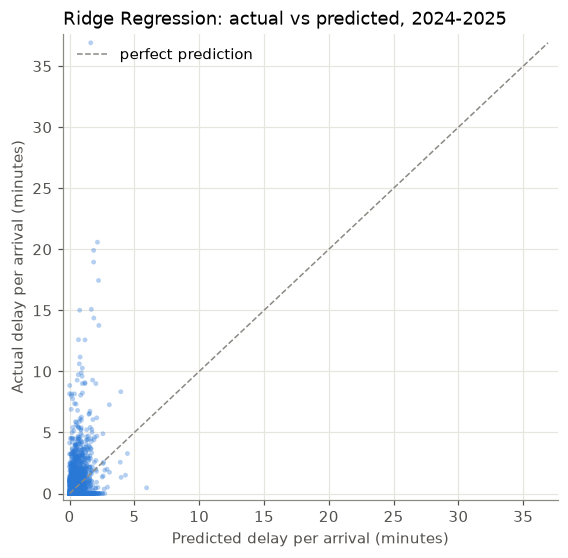

In [40]:
# 11.4 actual versus predicted on 2024-2025
# Each point is one test airport-day. Points on the dashed line were predicted exactly.
# common upper limit so both axes use the same scale
largest_value = max(test_values.max(), test_prediction.max())

fig, ax = plt.subplots(figsize=(5.8, 5.5))
ax.scatter(test_prediction, test_values, s=10, alpha=0.35, color=MODEL_COLOR, edgecolors="none")
ax.plot([0, largest_value], [0, largest_value], linestyle="--", color=REFERENCE_COLOR, linewidth=1,
        label="perfect prediction")
ax.set_xlabel("Predicted delay per arrival (minutes)")
ax.set_ylabel("Actual delay per arrival (minutes)")
ax.set_title("Ridge Regression: actual vs predicted, 2024-2025", loc="left")
ax.set_xlim(-0.5, largest_value * 1.02)
ax.set_ylim(-0.5, largest_value * 1.02)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper left")
plt.show()

Almost all predictions are below 3 minutes, while actual values reach 37, so severe days are never predicted as severe. The row of points along the bottom is calm days with a small positive prediction.

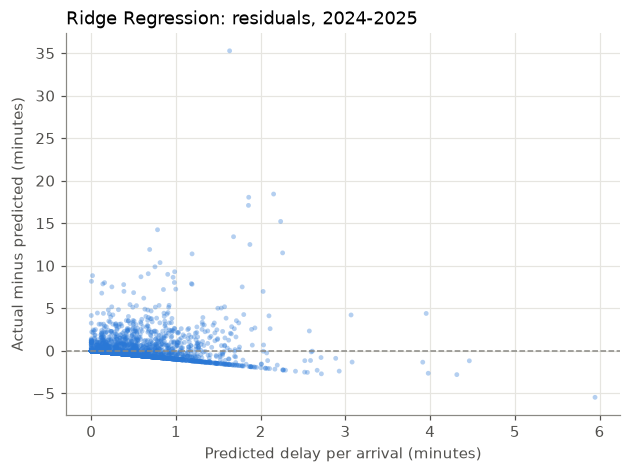

Days where the model was too low by more than 5 minutes:  45
Days where the model was too high by more than 5 minutes: 1


In [41]:
# 11.5 residuals (actual minus predicted) against the prediction
# Residuals show where the model is too low (positive) or too high (negative). A pattern
# against the prediction means the linear model misses part of the structure.
residuals = test_values - test_prediction

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.scatter(test_prediction, residuals, s=10, alpha=0.35, color=MODEL_COLOR, edgecolors="none")
ax.axhline(0, color=REFERENCE_COLOR, linestyle="--", linewidth=1)
ax.set_xlabel("Predicted delay per arrival (minutes)")
ax.set_ylabel("Actual minus predicted (minutes)")
ax.set_title("Ridge Regression: residuals, 2024-2025", loc="left")
ax.set_axisbelow(True)
plt.show()

print(f"Days where the model was too low by more than 5 minutes:  {(residuals > 5).sum()}")
print(f"Days where the model was too high by more than 5 minutes: {(residuals < -5).sum()}")

Residuals are strongly skewed: 45 days were under-predicted by more than 5 minutes and only 1 over-predicted by that much. The large misses are severe days predicted as ordinary.

In [42]:
# 11.6 does performance hold in both test years?
# Splits the test errors by year to see whether the result depends on one year only.
test_years = test_days["year"].to_numpy()
year_rows = []
for year in [2024, 2025]:
    in_year = test_years == year
    year_rows.append({
        "year": year,
        "rows": int(in_year.sum()),
        "mean_actual": test_values[in_year].mean(),
        "model_MAE": mean_absolute_error(test_values[in_year], test_prediction[in_year]),
        "benchmark_28d_MAE": mean_absolute_error(test_values[in_year], test_rolling[in_year]),
        # always predicting zero gives an absolute error equal to the actual value, so its MAE is the mean
        "always_zero_MAE": test_values[in_year].mean(),
        "model_RMSE": np.sqrt(mean_squared_error(test_values[in_year], test_prediction[in_year])),
        "benchmark_28d_RMSE": np.sqrt(mean_squared_error(test_values[in_year], test_rolling[in_year])),
    })
pd.DataFrame(year_rows).round(3)

,year,rows,mean_actual,model_MAE,benchmark_28d_MAE,always_zero_MAE,model_RMSE,benchmark_28d_RMSE
0,2024,4391,0.230,0.314,0.330,0.230,1.070,1.100
1,2025,4380,0.184,0.266,0.266,0.184,0.829,0.863


The pattern holds in both years: Ridge loses to always zero on MAE (0.314 vs 0.230 in 2024, 0.266 vs 0.184 in 2025) and beats the 28-day average on RMSE (1.070 vs 1.100, 0.829 vs 0.863).

## 12. Results by airport

`always_zero_MAE` equals the airport's mean delay, and `bias` is mean prediction minus mean actual. R² is left empty where an airport had no delay in 2024–2025. Neighbouring days are correlated, so a single bad week can dominate an airport's figures.

In [43]:
# 12.1 one row per airport for 2024-2025
# Test errors per airport, with the mean prediction minus the mean actual value as bias.
test_results = test_days[["airport_icao", "airport_name", "date", "year"]].copy()
test_results["actual"] = test_values
test_results["prediction"] = test_prediction
test_results["prediction_unclipped"] = test_prediction_raw
test_results["benchmark_28d"] = test_rolling

airport_rows = []
for airport, group in test_results.groupby("airport_icao"):
    row = {
        "airport": airport,
        "name": group["airport_name"].iloc[0],
        "days": len(group),
        "positive_days": int((group["actual"] > 0).sum()),
        "mean_actual": group["actual"].mean(),
        "mean_prediction": group["prediction"].mean(),
        "model_MAE": mean_absolute_error(group["actual"], group["prediction"]),
        "benchmark_28d_MAE": mean_absolute_error(group["actual"], group["benchmark_28d"]),
        # always-zero MAE equals the mean of the actual values, since the target is never negative
        "always_zero_MAE": group["actual"].mean(),
        "model_RMSE": np.sqrt(mean_squared_error(group["actual"], group["prediction"])),
        "benchmark_28d_RMSE": np.sqrt(mean_squared_error(group["actual"], group["benchmark_28d"])),
        "R2": np.nan,
    }
    # R2 is undefined when all actual values at an airport are the same
    if group["actual"].nunique() > 1:
        row["R2"] = r2_score(group["actual"], group["prediction"])
    row["bias"] = row["mean_prediction"] - row["mean_actual"]
    airport_rows.append(row)

airport_metrics = pd.DataFrame(airport_rows).sort_values("mean_actual", ascending=False)
airport_metrics.round(3)

,airport,name,days,positive_days,mean_actual,mean_prediction,model_MAE,benchmark_28d_MAE,always_zero_MAE,model_RMSE,benchmark_28d_RMSE,R2,bias
1,EDDF,Frankfurt,731,297,1.111,0.934,1.302,1.499,1.111,2.666,2.784,0.067,-0.177
4,EDDK,Cologne-Bonn,731,216,0.473,0.367,0.532,0.619,0.473,0.933,0.983,0.126,-0.106
6,EDDM,Munich,731,214,0.382,0.385,0.487,0.525,0.382,1.000,1.047,0.123,0.003
8,EDDP,Leipzig-Halle,731,80,0.203,0.171,0.316,0.363,0.203,0.876,0.883,-0.010,-0.032
9,EDDS,Stuttgart,731,70,0.201,0.148,0.297,0.353,0.201,0.883,0.898,0.016,-0.054
5,EDDL,Duesseldorf,731,44,0.084,0.128,0.183,0.158,0.084,0.494,0.509,0.025,0.044
3,EDDH,Hamburg,731,19,0.025,0.126,0.141,0.048,0.025,0.301,0.232,-0.727,0.100
11,EDDW,Bremen,731,1,0.004,0.070,0.074,0.009,0.004,0.227,0.122,-2.590,0.065
7,EDDN,Nuremberg,731,1,0.002,0.021,0.022,0.003,0.002,0.085,0.041,-3.327,0.019
2,EDDG,Muenster-Osnabrueck,731,1,0.001,0.045,0.046,0.003,0.001,0.172,0.038,-20.574,0.044


- Frankfurt has the most delay (mean 1.11). Ridge's MAE there (1.30) is worse than always zero (1.11) but better than the 28-day average (1.50); R² is only 0.07 and the bias is −0.18.
- Cologne-Bonn and Munich have R² of about 0.12–0.13.
- At the quiet airports Ridge predicts small positive delays (0.02–0.07), which makes its MAE worse than every benchmark there and the airport-level R² strongly negative (−20 at Münster-Osnabrück, whose mean is almost exactly zero).
- Hamburg has a positive bias (+0.10), since it was more delayed in the training years than in 2024–2025.

## 13. Interpretation

Coefficients are in minutes per arrival per standard deviation of the input, holding the others fixed. Permutation importance on 2023 uses RMSE, because the model is fitted to squared error and the signal concerns the size of delays on bad days; this is descriptive and affects no decision. Correlated inputs share influence, and neither view identifies causes of delay.

In [44]:
# 13.1 coefficients of the frozen model (minutes per arrival per one standard deviation)
# The fitted coefficients. Numeric predictors were standardized, so each coefficient is the change in
# minutes per arrival for one standard deviation; the airport coefficients are shifts for a 0/1 column.
# named_steps gives access to the individual steps of the fitted Pipeline
regressor = final_model.named_steps["regressor"]
feature_names = final_model.named_steps["preprocess"].get_feature_names_out()

coefficients = pd.DataFrame({"feature": feature_names, "coefficient": regressor.coef_})
# drop the prefixes ColumnTransformer adds to the output column names
coefficients["feature"] = coefficients["feature"].str.replace("numeric__", "").str.replace("airport__", "")
coefficients = coefficients.sort_values("coefficient", ascending=False)

print(f"Intercept: {regressor.intercept_:.3f}")
print("Ten largest positive coefficients:")
# display() shows a DataFrame as a table in the middle of a cell
display(coefficients.head(10).round(3))
print("Ten largest negative coefficients:")
display(coefficients.tail(10).round(3))

Intercept: 0.192
Ten largest positive coefficients:


,feature,coefficient
23,thunder_hours,0.110
30,share_delayed15_lag1,0.098
18,cold_precip_hours,0.095
27,arrivals_lag7,0.091
32,delay_per_arrival_mean_7d,0.087
20,low_vis_hours_lt1000,0.086
34,disrupted_rate_28d,0.064
33,delay_per_arrival_mean_28d,0.064
13,gust_max_ms,0.041
44,airport_icao_EDDP,0.040


Ten largest negative coefficients:


,feature,coefficient
35,weather_delay_per_arrival_mean_28d,-0.015
5,is_public_holiday,-0.017
38,airport_icao_EDDG,-0.018
46,airport_icao_EDDV,-0.018
3,doy_cos,-0.020
19,vis_min_m,-0.021
6,temp_mean_c,-0.023
4,is_weekend,-0.025
17,precip_hours,-0.036
42,airport_icao_EDDM,-0.117


With alpha = 1,000 all coefficients are shrunk, but the ordering is informative.
- Largest positive effects (minutes per arrival per SD): thunderstorm hours (+0.110), yesterday's share of flights delayed more than 15 minutes (+0.098), cold precipitation hours as a snow and ice proxy (+0.095), arrivals a week earlier (+0.091), the 7-day mean delay (+0.087) and low-visibility hours (+0.086).
- Munich's airport indicator is clearly negative (−0.12): less delay than its traffic level would suggest.
- Precipitation hours are negative while thunderstorm and cold-precipitation hours are positive; these columns overlap and should not be read individually.

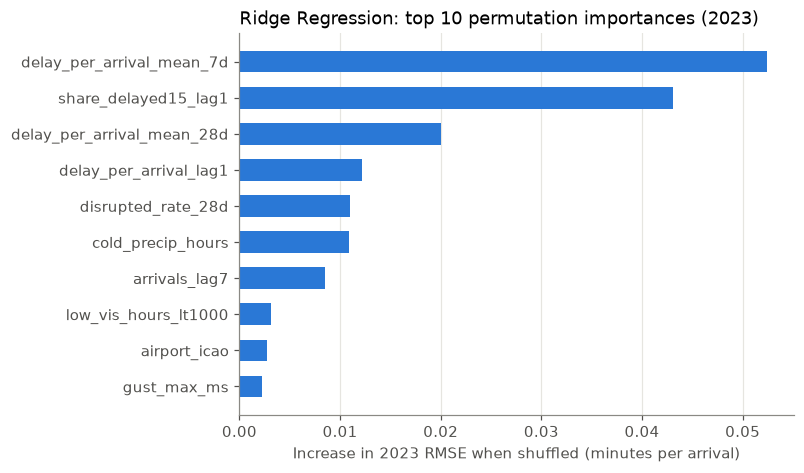

,feature,RMSE_increase_mean,RMSE_increase_std
33,delay_per_arrival_mean_7d,0.0524,0.0015
31,share_delayed15_lag1,0.0431,0.0014
34,delay_per_arrival_mean_28d,0.0200,0.0008
30,delay_per_arrival_lag1,0.0122,0.0005
35,disrupted_rate_28d,0.0110,0.0007
19,cold_precip_hours,0.0109,0.0012
28,arrivals_lag7,0.0085,0.0014
21,low_vis_hours_lt1000,0.0031,0.0009
0,airport_icao,0.0027,0.0009
14,gust_max_ms,0.0022,0.0003


In [45]:
# 13.2 permutation importance on 2023 (increase in RMSE when a column is shuffled)
# Permutation importance on 2023: shuffle one column at a time and measure how much RMSE increases.
# It is measured on data the model was not trained on, and it works on the original (unencoded) columns.
from sklearn.inspection import permutation_importance

# sklearn scores are "higher is better", so RMSE is passed as its negative; the mean drop in that score
# is the increase in RMSE. n_repeats=5 shuffles each column five times.
permutation = permutation_importance(
    final_model, X_calibrate, y_calibrate,
    scoring="neg_root_mean_squared_error", n_repeats=5, random_state=RANDOM_SEED,
)
permutation_table = pd.DataFrame({
    "feature": X_calibrate.columns,
    "RMSE_increase_mean": permutation.importances_mean,
    "RMSE_increase_std": permutation.importances_std,
}).sort_values("RMSE_increase_mean", ascending=False)

top_permutation = permutation_table.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.barh(top_permutation["feature"], top_permutation["RMSE_increase_mean"], color=MODEL_COLOR, height=0.6)
ax.set_xlabel("Increase in 2023 RMSE when shuffled (minutes per arrival)")
ax.set_title("Ridge Regression: top 10 permutation importances (2023)", loc="left")
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)
plt.show()

permutation_table.head(10).round(4)

The largest increases in 2023 RMSE come from the 7-day mean delay (+0.052), yesterday's share delayed more than 15 minutes (+0.043), the 28-day mean delay (+0.020) and yesterday's delay per arrival (+0.012). Cold precipitation (+0.011) is the strongest weather input. Thunderstorm hours have the largest coefficient but are not in the top 10; thunderstorm days are rare, and the thunderstorm column is missing on 353 days in 2023. All increases are small relative to a 2023 RMSE of about 1.3.

In [46]:
# 13.3 the ten test days with the largest absolute errors (description only)
# The largest test errors with the delay causes and weather of that day, to describe what the model misses.
# These causes are same-day outcomes and are only used here for description, never as predictors.
test_results["absolute_error"] = (test_results["actual"] - test_results["prediction"]).abs()
largest_errors = test_results.sort_values("absolute_error", ascending=False).head(10)
largest_errors = largest_errors.merge(
    test_days[["airport_icao", "date", "arrivals", "delay_weather_min", "delay_atc_capacity_min",
               "delay_atc_staffing_min", "delay_aerodrome_capacity_min", "thunder_hours", "gust_max_ms"]],
    on=["airport_icao", "date"],
)
largest_errors["date"] = largest_errors["date"].dt.date
largest_errors[[
    "airport_icao", "date", "actual", "prediction", "benchmark_28d", "arrivals",
    "delay_weather_min", "delay_atc_capacity_min", "delay_atc_staffing_min", "delay_aerodrome_capacity_min",
    "thunder_hours", "gust_max_ms",
]].round(2)

,airport_icao,date,actual,prediction,benchmark_28d,arrivals,delay_weather_min,delay_atc_capacity_min,delay_atc_staffing_min,delay_aerodrome_capacity_min,thunder_hours,gust_max_ms
0,EDDF,2024-11-19,36.91,1.63,3.15,522.0,0.0,0.0,0.0,19266.0,0.0,20.1
1,EDDF,2024-11-12,20.58,2.15,2.56,546.0,0.0,0.0,0.0,11237.0,0.0,8.9
2,EDDF,2025-07-27,19.91,1.86,2.01,654.0,13020.0,0.0,0.0,0.0,0.0,10.7
3,EDDF,2024-01-17,18.95,1.86,1.00,183.0,3468.0,0.0,0.0,0.0,0.0,5.4
4,EDDF,2024-10-28,17.44,2.24,0.65,585.0,10205.0,0.0,0.0,0.0,0.0,6.5
5,EDDF,2024-07-25,15.01,0.78,1.05,543.0,0.0,0.0,0.0,0.0,0.0,7.0
6,EDDF,2025-07-25,15.09,1.68,1.42,659.0,9943.0,0.0,0.0,0.0,0.0,13.5
7,EDDF,2024-12-01,14.37,1.87,3.33,562.0,5286.0,0.0,0.0,2789.0,0.0,5.8
8,EDDP,2024-06-18,12.60,0.69,0.53,134.0,1688.0,0.0,0.0,0.0,0.0,13.2
9,EDDF,2025-01-05,13.77,2.26,1.25,470.0,5500.0,0.0,0.0,0.0,0.0,7.7


Nine of the ten largest misses are at Frankfurt, all under-predictions of severe days.
- The largest is 19 November 2024: 36.9 minutes per arrival against a prediction of 1.6, coded as aerodrome capacity (19,266 minutes), with gusts of 20 m/s. 12 November 2024 was also an aerodrome-capacity day.
- Most others are weather-coded although the airport station recorded no thunderstorm hours; low cloud, wind direction, network-wide weather or the hourly timing are not captured by daily station summaries.
- 17 January 2024 had only 183 arrivals at Frankfurt, pointing to a major disruption that the inputs do not reflect.

## 14. Saving outputs

Saves the frozen pipeline (with fitted preprocessing), the clipping rule, predictor list, settings and versions to `outputs/05_ridge_regression/model.joblib`, together with the test predictions, test metrics, airport metrics and tuning results as CSV, then reloads the model as a check.

In [47]:
# 14.1 save everything needed to reuse and check this model
# Saves the model, the clipping decision, the settings and the result tables, so notebook 06 can build
# its comparison from them without retraining.
import joblib

OUTPUT_DIR = PROJECT_ROOT / "outputs" / "05_ridge_regression"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

saved_model = {
    "model": final_model,
    "clip_predictions_at_zero": clip_predictions,
    "predictor_columns": predictor_columns,
    "settings": {"alpha": best_alpha, "random_seed": RANDOM_SEED},
    "training_years": "2014-2021",
    "description": "ridge regression pipeline (median fill + standardize + one-hot airport) with the chosen alpha",
    "versions": {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
                 "scikit-learn": sklearn.__version__},
}
# joblib stores the fitted pipeline plus metadata in one file
joblib.dump(saved_model, OUTPUT_DIR / "model.joblib")

# Adds the 2022 selection MAE to the model's row of the test table
test_metrics.loc[test_metrics["rule"] == "Ridge Regression", "select_2022_MAE"] = mean_absolute_error(y_select, final_select_prediction)

test_results.to_csv(OUTPUT_DIR / "test_predictions_2024_2025.csv", index=False)
test_metrics.to_csv(OUTPUT_DIR / "test_metrics.csv", index=False)
airport_metrics.to_csv(OUTPUT_DIR / "airport_metrics.csv", index=False)
tuning_results.to_csv(OUTPUT_DIR / "tuning_results.csv", index=False)


for saved_file in sorted(OUTPUT_DIR.iterdir()):
    print(saved_file.name)

airport_metrics.csv
model.joblib
test_metrics.csv
test_predictions_2024_2025.csv
tuning_results.csv


In [48]:
# 14.2 reload the saved model and check it reproduces the saved predictions
# Loads the saved file again and checks it reproduces the test predictions, including the clipping step.
reloaded = joblib.load(OUTPUT_DIR / "model.joblib")
reloaded_prediction = reloaded["model"].predict(X_test)
if reloaded["clip_predictions_at_zero"]:
    reloaded_prediction = np.clip(reloaded_prediction, 0, None)
print("Reloaded model gives identical test predictions:", np.allclose(reloaded_prediction, test_prediction))

Reloaded model gives identical test predictions: True


The reloaded model, with the saved clipping rule, reproduces the test predictions exactly.

## Summary

- 2024–2025 MAE 0.290, against 0.207 for always zero and 0.298 for the 28-day average: Ridge does not beat always zero on the main metric.
- RMSE 0.957 and R² 0.14, the best RMSE of all rules; the mean prediction (0.2065) matches the actual mean (0.207).
- Severe days are badly under-predicted: no prediction exceeds about 6 minutes, while actual values reach 37.
- About 40% of raw predictions are negative, so predictions are clipped at zero (decided on 2023); this improved test MAE by 0.034.
- The penalty strength has almost no effect with this much data.

Notebook 06 fits LightGBM on the same rows.